In [1]:
import numpy
import pandas
import networkx as nx
import matplotlib.pyplot as plt

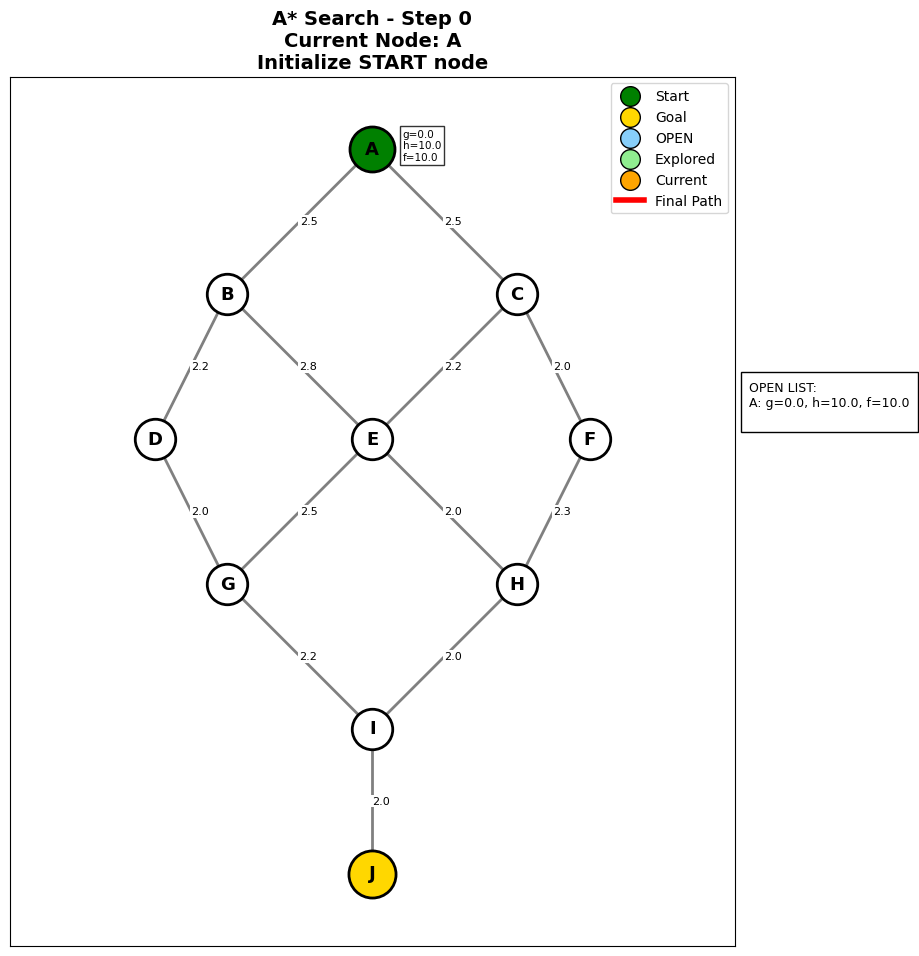

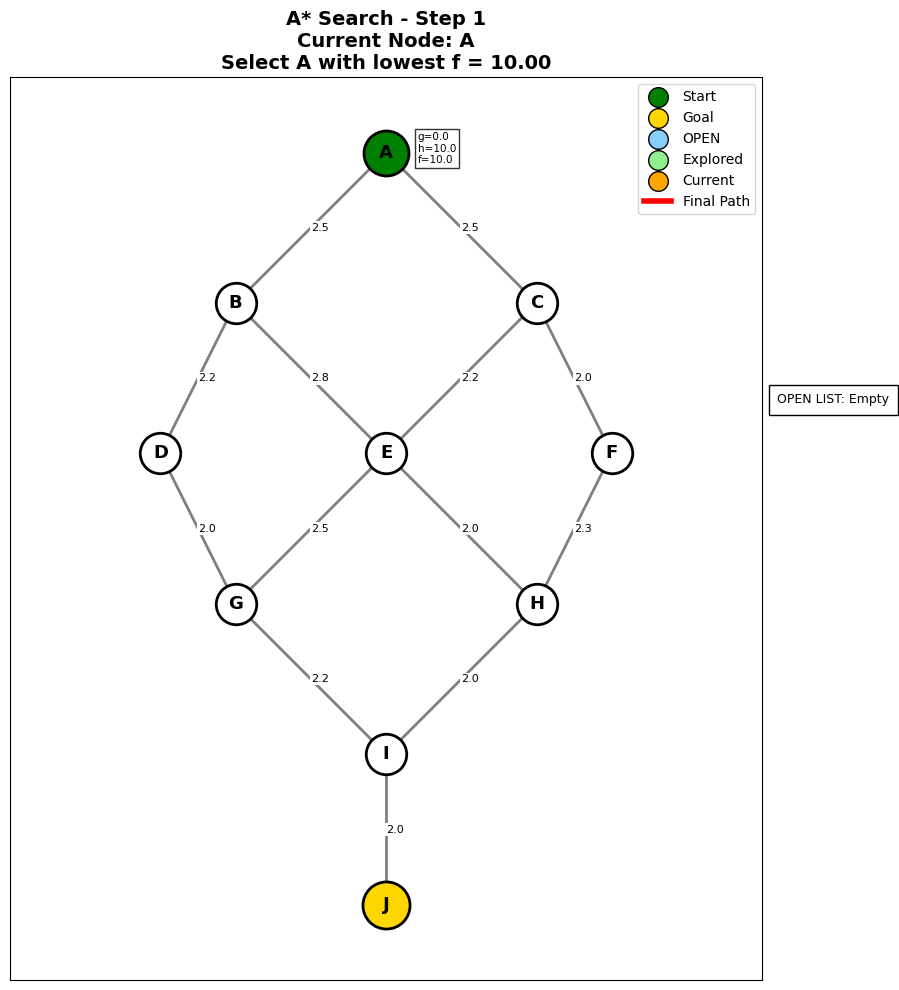

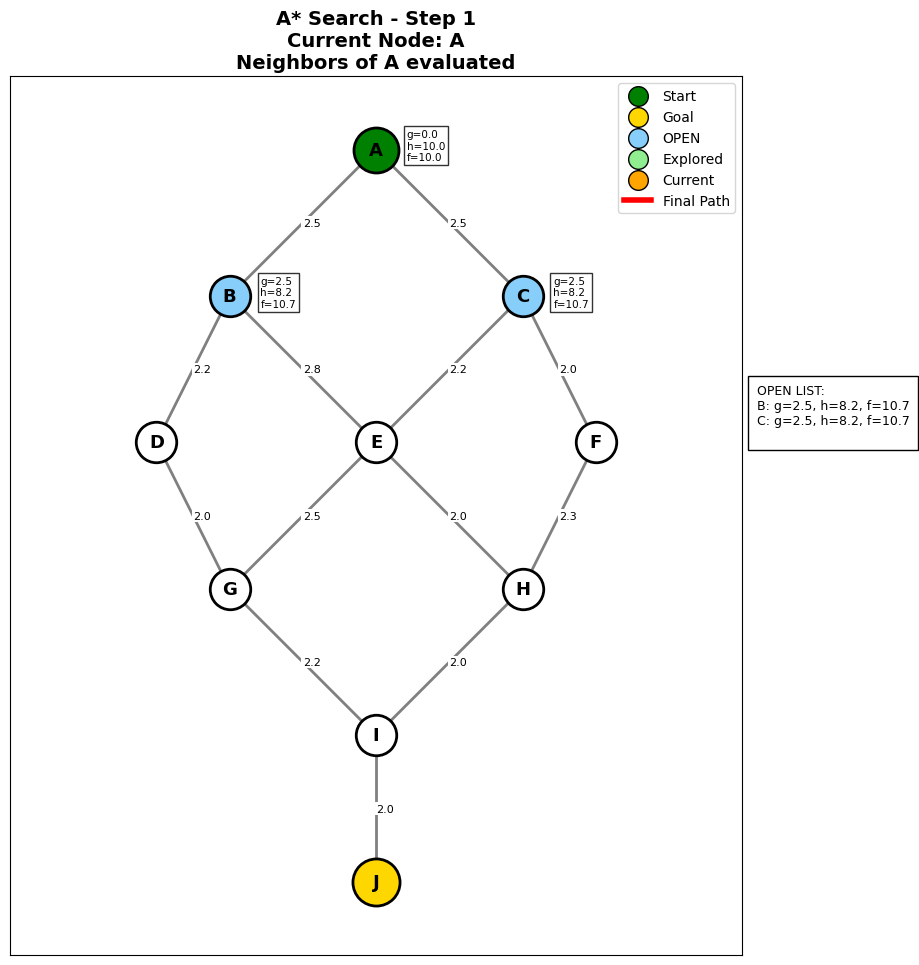

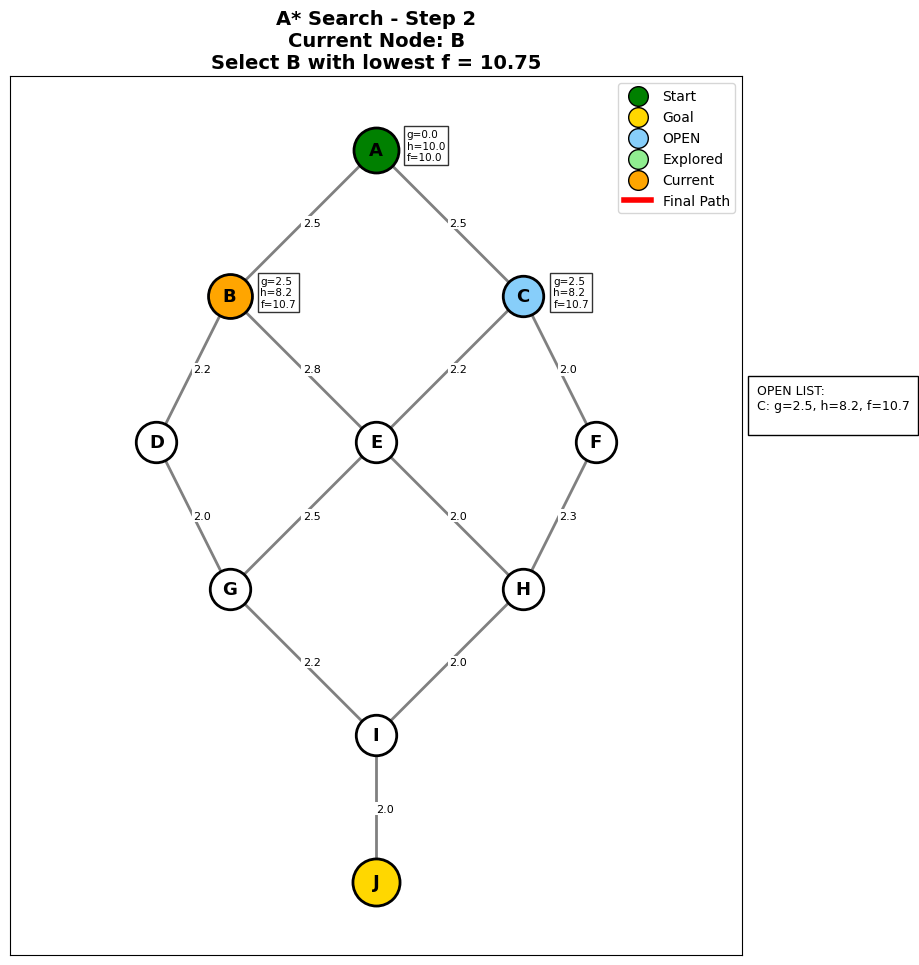

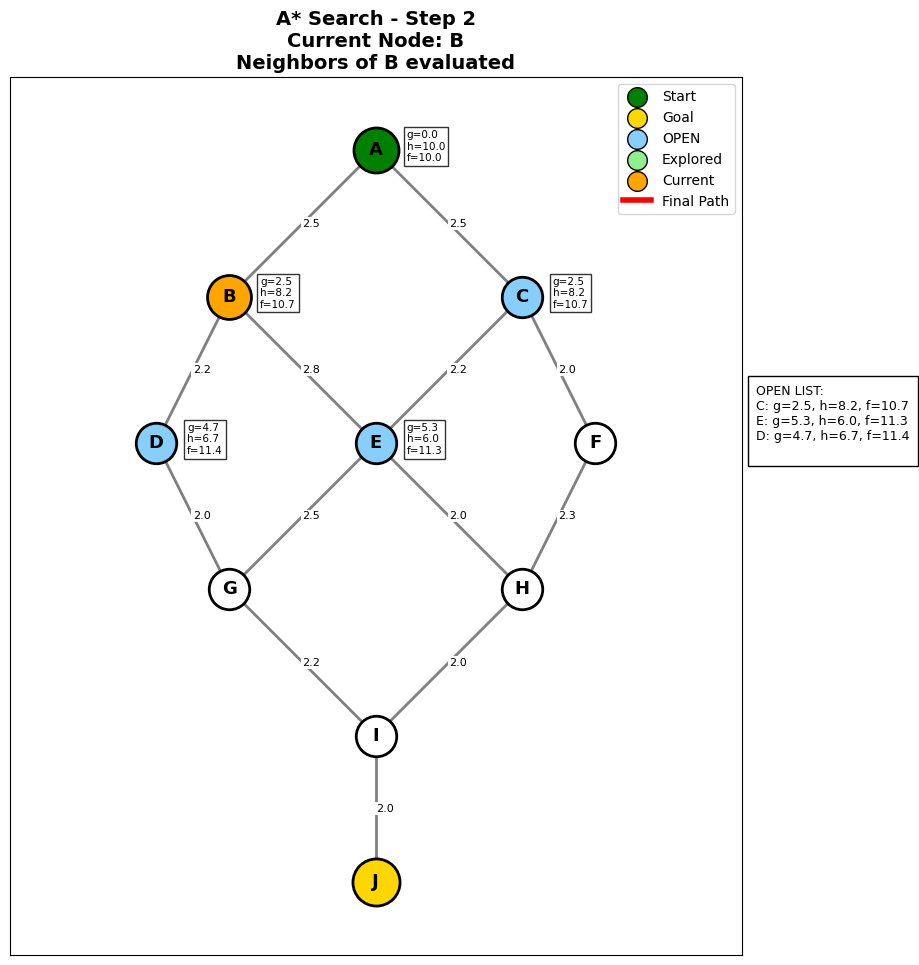

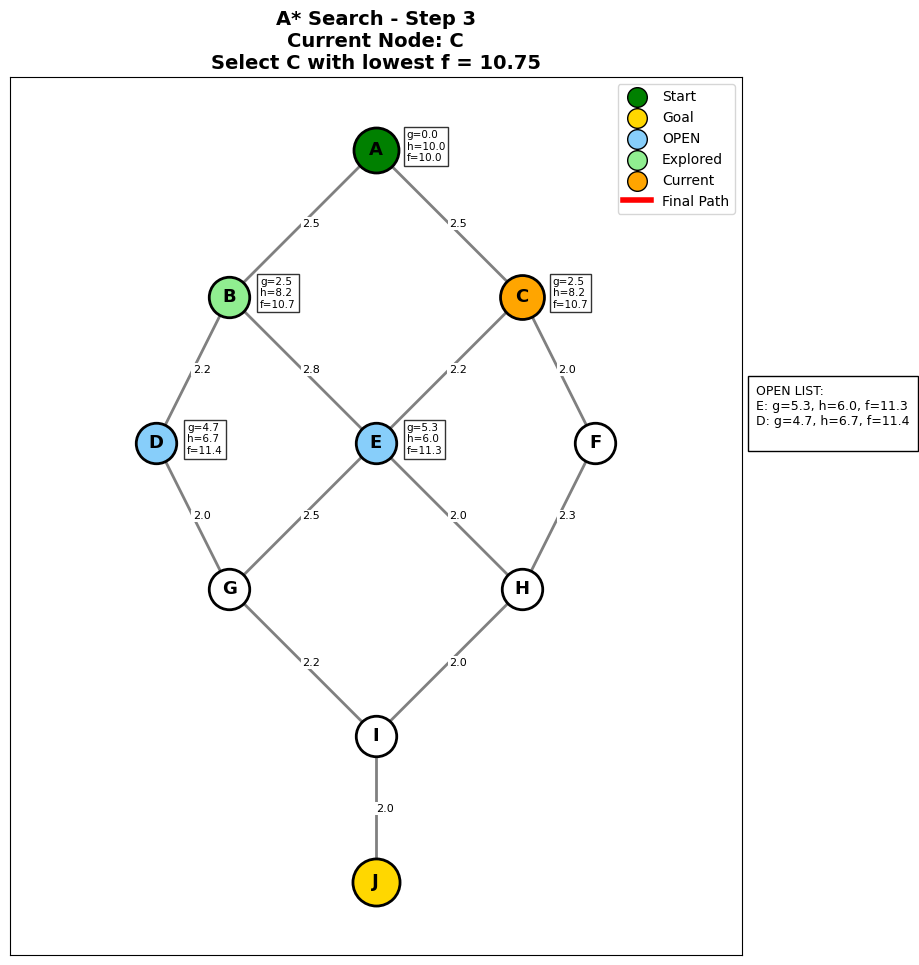

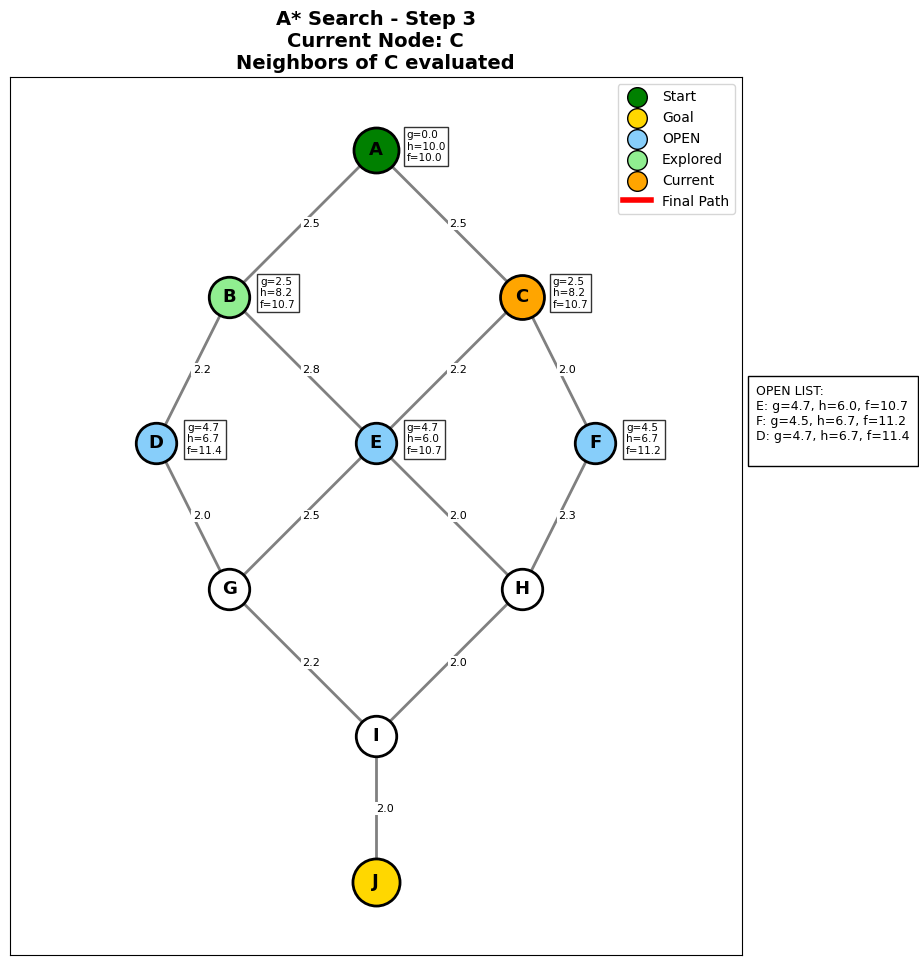

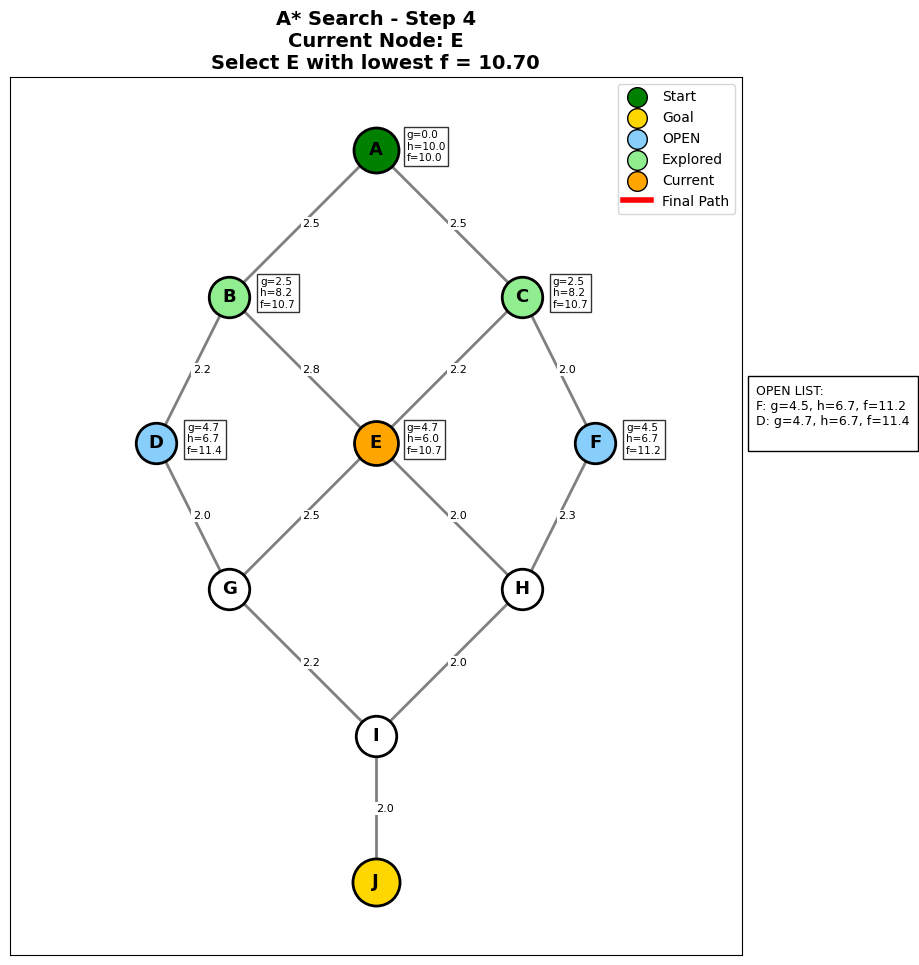

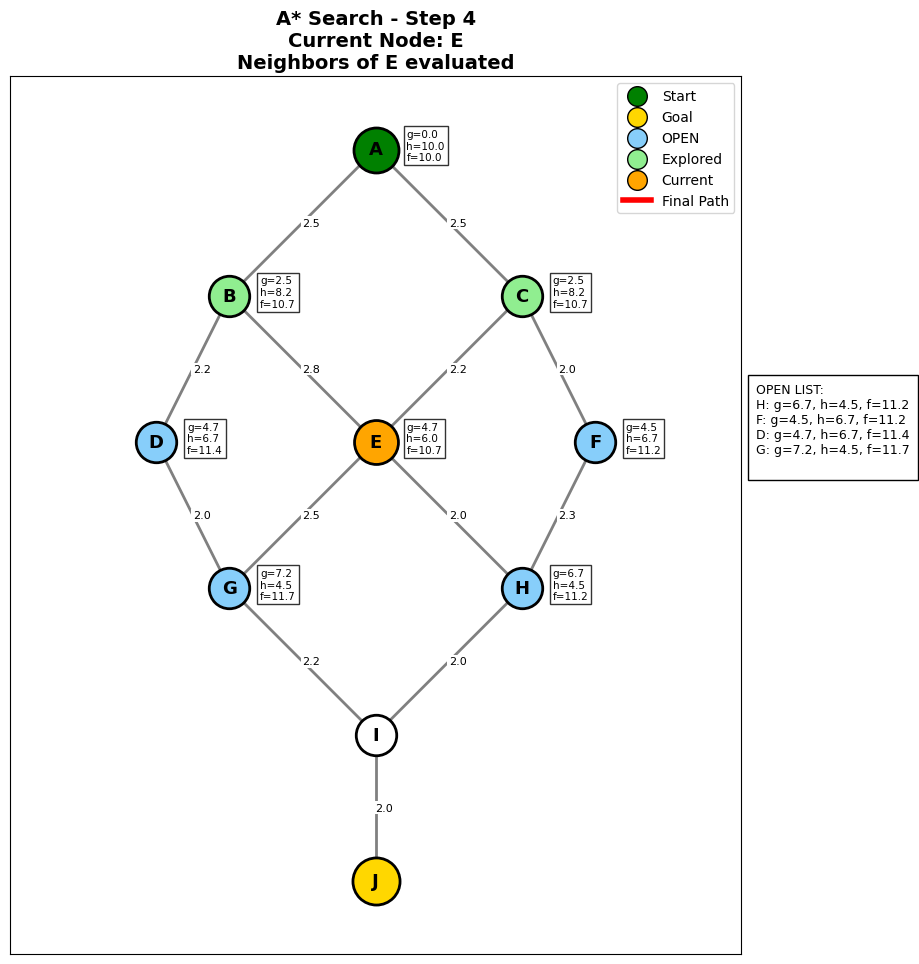

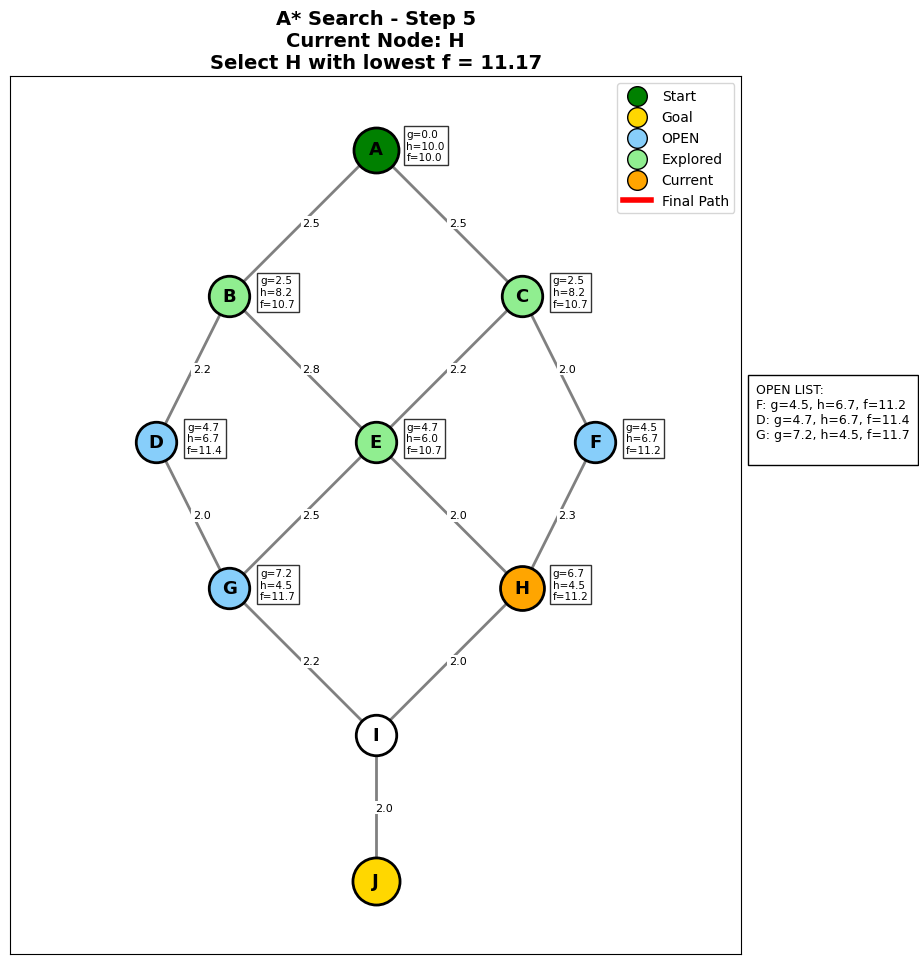

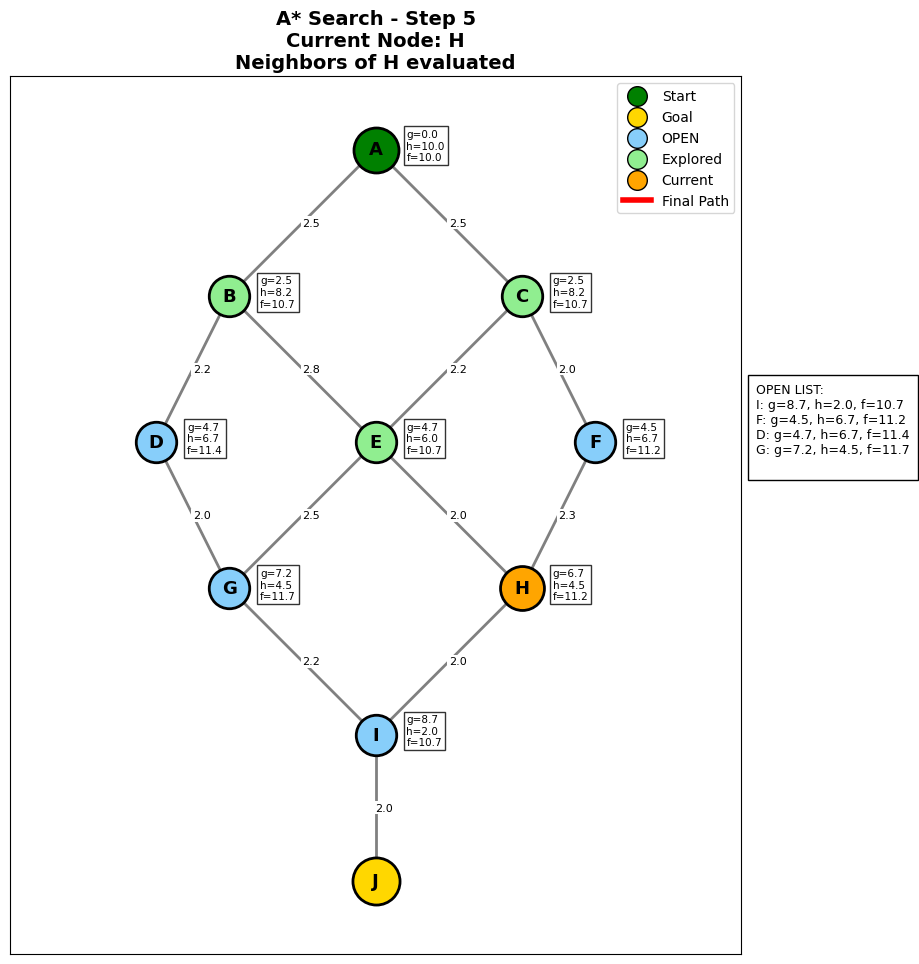

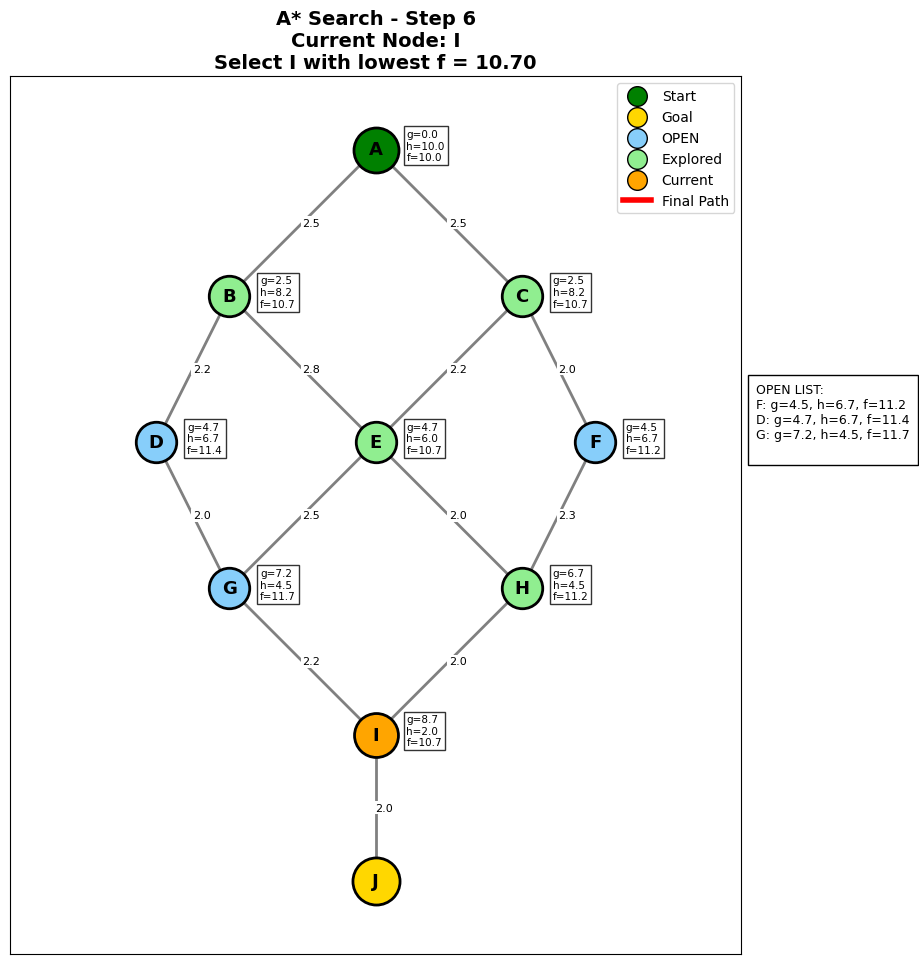

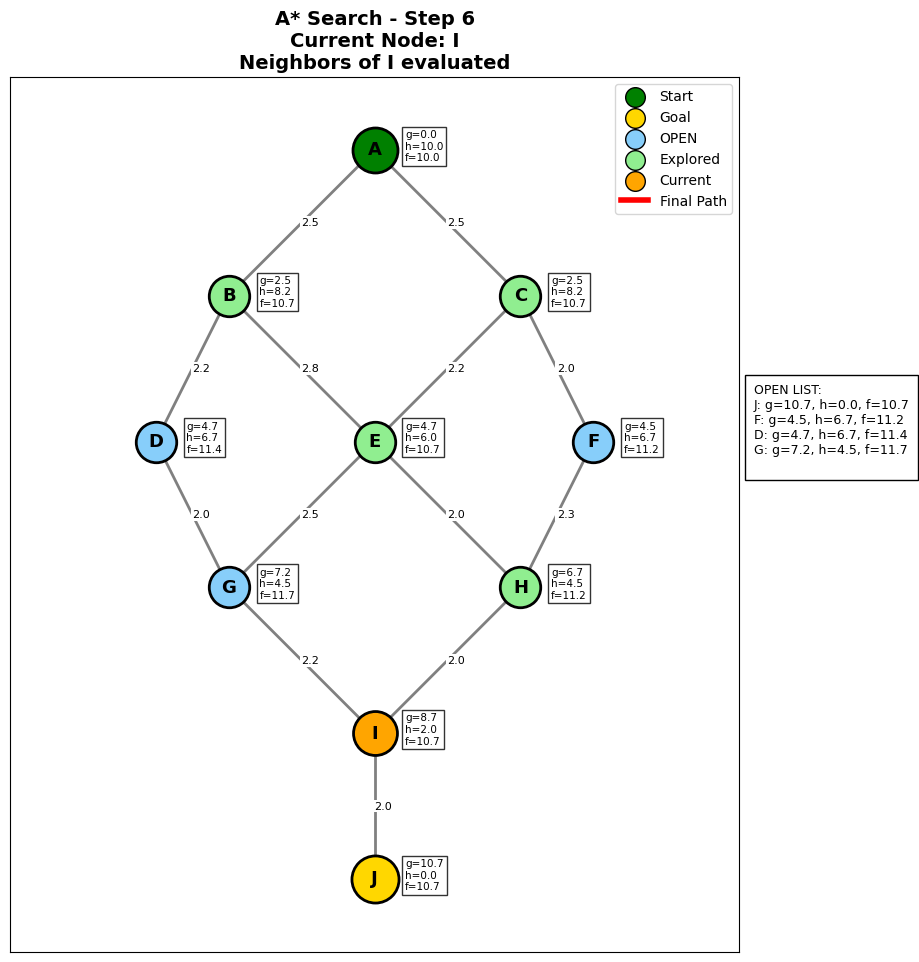

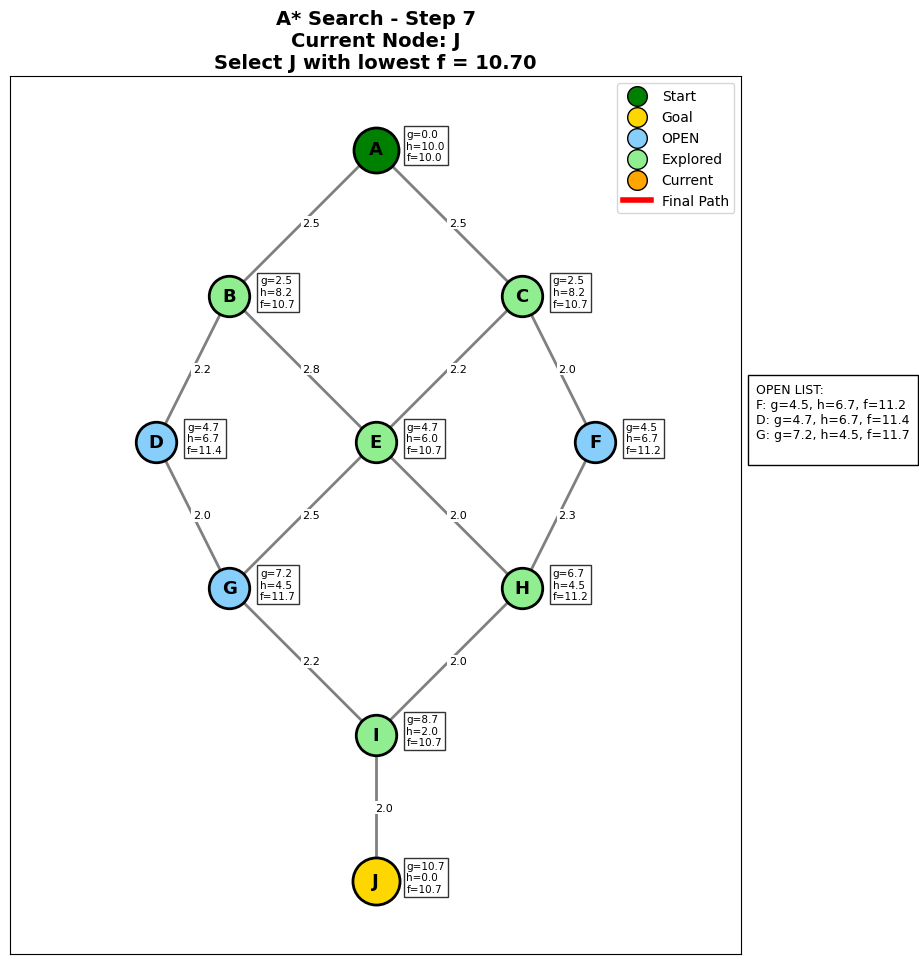

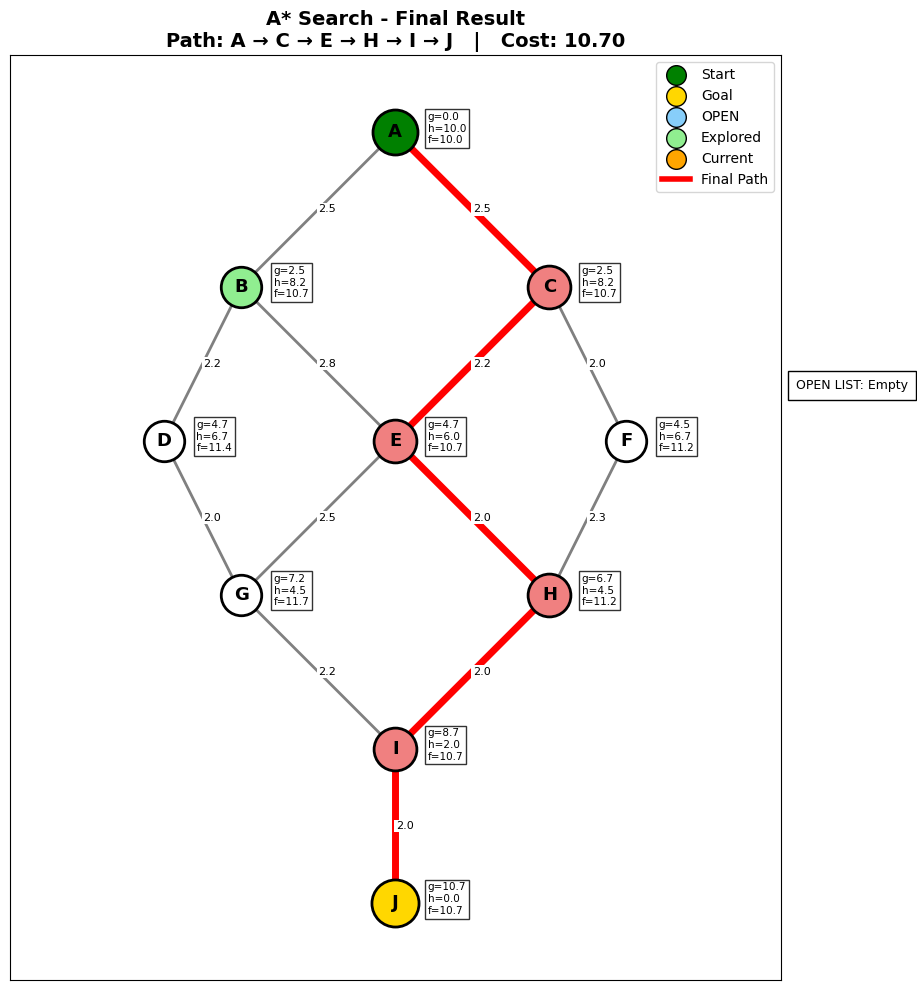


A* SEARCH COMPLETE
Path: A -> C -> E -> H -> I -> J
Cost: 10.7
Explored: ['A', 'B', 'C', 'E', 'H', 'I', 'J']


In [18]:
import heapq
import math
import matplotlib.pyplot as plt


# ============================================================
# NODE
# ============================================================

class Node:
    def __init__(self, name, x, y):
        self.name = name
        self.x = x
        self.y = y

        self.g = float("inf")
        self.h = 0
        self.f = float("inf")

        self.parent = None


# ============================================================
# HEURISTIC
# ============================================================

def heuristic(node, goal):

    return math.sqrt(
        (node.x - goal.x) ** 2 +
        (node.y - goal.y) ** 2
    )


# ============================================================
# CREATE GRAPH
# ============================================================

def create_graph():

    # Start at top, goal at bottom

    A = Node("A", 0, 10)

    B = Node("B", -2, 8)
    C = Node("C", 2, 8)

    D = Node("D", -3, 6)
    E = Node("E", 0, 6)
    F = Node("F", 3, 6)

    G = Node("G", -2, 4)
    H = Node("H", 2, 4)

    I = Node("I", 0, 2)

    J = Node("J", 0, 0)

    nodes = {
        "A": A,
        "B": B,
        "C": C,
        "D": D,
        "E": E,
        "F": F,
        "G": G,
        "H": H,
        "I": I,
        "J": J
    }

    graph = {

        A: [(B, 2.5), (C, 2.5)],

        B: [
            (A, 2.5),
            (D, 2.2),
            (E, 2.8)
        ],

        C: [
            (A, 2.5),
            (E, 2.2),
            (F, 2.0)
        ],

        D: [
            (B, 2.2),
            (G, 2.0)
        ],

        E: [
            (B, 2.8),
            (C, 2.2),
            (G, 2.5),
            (H, 2.0)
        ],

        F: [
            (C, 2.0),
            (H, 2.3)
        ],

        G: [
            (D, 2.0),
            (E, 2.5),
            (I, 2.2)
        ],

        H: [
            (E, 2.0),
            (F, 2.3),
            (I, 2.0)
        ],

        I: [
            (G, 2.2),
            (H, 2.0),
            (J, 2.0)
        ],

        J: [
            (I, 2.0)
        ]
    }

    return nodes, graph


# ============================================================
# DRAW CURRENT STEP
# ============================================================

def draw_step(
        graph,
        start,
        goal,
        explored,
        open_nodes,
        current=None,
        final_path=None,
        step=0,
        message=""
):

    plt.clf()

    fig = plt.gcf()
    fig.set_size_inches(9, 10)

    ax = plt.gca()

    # ========================================================
    # DRAW EDGES
    # ========================================================

    drawn_edges = set()

    for node in graph:

        for neighbor, cost in graph[node]:

            edge = frozenset([node, neighbor])

            if edge in drawn_edges:
                continue

            drawn_edges.add(edge)

            # Final path edge
            is_path_edge = False

            if final_path and node in final_path and neighbor in final_path:

                node_index = final_path.index(node)
                neighbor_index = final_path.index(neighbor)

                if abs(node_index - neighbor_index) == 1:
                    is_path_edge = True

            if is_path_edge:

                edge_color = "red"
                edge_width = 5
                edge_zorder = 4

            else:

                edge_color = "gray"
                edge_width = 2
                edge_zorder = 1

            ax.plot(
                [node.x, neighbor.x],
                [node.y, neighbor.y],
                color=edge_color,
                linewidth=edge_width,
                zorder=edge_zorder
            )

            # Edge cost
            mid_x = (node.x + neighbor.x) / 2
            mid_y = (node.y + neighbor.y) / 2

            ax.text(
                mid_x + 0.12,
                mid_y,
                str(cost),
                fontsize=8,
                ha="center",
                va="center",
                bbox=dict(
                    facecolor="white",
                    edgecolor="none",
                    pad=1
                ),
                zorder=5
            )

    # ========================================================
    # DRAW NODES
    # ========================================================

    for node in graph:

        # Default
        node_color = "white"
        node_size = 850

        # Explored
        if node in explored:
            node_color = "lightgreen"

        # Open list
        if node in open_nodes:
            node_color = "lightskyblue"

        # Current node
        if node == current:
            node_color = "orange"
            node_size = 1000

        # Final path
        if final_path and node in final_path:
            node_color = "lightcoral"
            node_size = 950

        # Start
        if node == start:
            node_color = "green"
            node_size = 1050

        # Goal
        if node == goal:
            node_color = "gold"
            node_size = 1150

        ax.scatter(
            node.x,
            node.y,
            s=node_size,
            color=node_color,
            edgecolors="black",
            linewidth=2,
            zorder=6
        )

        # Node name
        ax.text(
            node.x,
            node.y,
            node.name,
            fontsize=13,
            fontweight="bold",
            ha="center",
            va="center",
            zorder=10
        )

        # ====================================================
        # SHOW G, H, F
        # ====================================================

        if node.g != float("inf"):

            info = (
                f"g={node.g:.1f}\n"
                f"h={node.h:.1f}\n"
                f"f={node.f:.1f}"
            )

            ax.text(
                node.x + 0.42,
                node.y + 0.05,
                info,
                fontsize=7.5,
                ha="left",
                va="center",
                bbox=dict(
                    facecolor="white",
                    edgecolor="black",
                    alpha=0.8,
                    pad=2
                ),
                zorder=20
            )

    # ========================================================
    # TITLE
    # ========================================================

    if final_path:

        path_names = " → ".join(
            node.name for node in final_path
        )

        cost = final_path[-1].g

        title = (
            f"A* Search - Final Result\n"
            f"Path: {path_names}   |   "
            f"Cost: {cost:.2f}"
        )

    else:

        current_name = (
            current.name
            if current is not None
            else "-"
        )

        title = (
            f"A* Search - Step {step}\n"
            f"Current Node: {current_name}\n"
            f"{message}"
        )

    ax.set_title(
        title,
        fontsize=14,
        fontweight="bold"
    )

    # ========================================================
    # OPEN LIST INFORMATION
    # ========================================================

    open_sorted = sorted(
        open_nodes,
        key=lambda n: (n.f, n.name)
    )

    if open_sorted:

        open_text = "OPEN LIST:\n"

        for node in open_sorted:

            open_text += (
                f"{node.name}: "
                f"g={node.g:.1f}, "
                f"h={node.h:.1f}, "
                f"f={node.f:.1f}\n"
            )

    else:

        open_text = "OPEN LIST: Empty"

    ax.text(
        1.02,
        0.65,
        open_text,
        transform=ax.transAxes,
        fontsize=9,
        verticalalignment="top",
        bbox=dict(
            facecolor="white",
            edgecolor="black",
            pad=6
        )
    )

    # ========================================================
    # LEGEND
    # ========================================================

    ax.scatter(
        [],
        [],
        s=200,
        color="green",
        edgecolors="black",
        label="Start"
    )

    ax.scatter(
        [],
        [],
        s=200,
        color="gold",
        edgecolors="black",
        label="Goal"
    )

    ax.scatter(
        [],
        [],
        s=200,
        color="lightskyblue",
        edgecolors="black",
        label="OPEN"
    )

    ax.scatter(
        [],
        [],
        s=200,
        color="lightgreen",
        edgecolors="black",
        label="Explored"
    )

    ax.scatter(
        [],
        [],
        s=200,
        color="orange",
        edgecolors="black",
        label="Current"
    )

    ax.plot(
        [],
        [],
        color="red",
        linewidth=4,
        label="Final Path"
    )

    ax.legend(
        loc="upper right"
    )

    # ========================================================
    # FORMATTING
    # ========================================================

    ax.set_xlim(-5, 5)
    ax.set_ylim(-1, 11)

    ax.set_aspect("equal")

    ax.set_xticks([])
    ax.set_yticks([])

    ax.grid(
        True,
        linestyle="--",
        alpha=0.2
    )

    plt.tight_layout()

    # Pause so the step can be seen
    plt.pause(1.5)


# ============================================================
# A* SEARCH WITH VISUALIZATION
# ============================================================

def a_star(graph, start, goal):

    # Reset nodes
    for node in graph:

        node.g = float("inf")
        node.h = 0
        node.f = float("inf")
        node.parent = None

    # ========================================================
    # INITIALIZE START
    # ========================================================

    start.g = 0
    start.h = heuristic(start, goal)
    start.f = start.g + start.h

    open_list = []

    heapq.heappush(
        open_list,
        (start.f, start.name, start)
    )

    closed = set()

    explored = []

    step = 0

    # ========================================================
    # INITIAL SCREEN
    # ========================================================

    draw_step(
        graph,
        start,
        goal,
        explored,
        {start},
        current=start,
        step=step,
        message="Initialize START node"
    )

    # ========================================================
    # SEARCH
    # ========================================================

    while open_list:

        _, _, current = heapq.heappop(open_list)

        if current in closed:
            continue

        # ----------------------------------------------------
        # Current node selected
        # ----------------------------------------------------

        step += 1

        closed.add(current)
        explored.append(current)

        open_nodes = {
            item[2]
            for item in open_list
            if item[2] not in closed
        }

        draw_step(
            graph,
            start,
            goal,
            explored,
            open_nodes,
            current=current,
            step=step,
            message=(
                f"Select {current.name} "
                f"with lowest f = {current.f:.2f}"
            )
        )

        # ----------------------------------------------------
        # Goal reached
        # ----------------------------------------------------

        if current == goal:

            path = []

            node = goal

            while node is not None:

                path.append(node)
                node = node.parent

            path.reverse()

            draw_step(
                graph,
                start,
                goal,
                explored,
                set(),
                current=goal,
                final_path=path,
                step=step,
                message="Goal reached!"
            )

            return path, explored

        # ----------------------------------------------------
        # Examine neighbors
        # ----------------------------------------------------

        for neighbor, cost in graph[current]:

            if neighbor in closed:
                continue

            new_g = current.g + cost

            if new_g < neighbor.g:

                neighbor.g = new_g
                neighbor.h = heuristic(
                    neighbor,
                    goal
                )
                neighbor.f = (
                    neighbor.g +
                    neighbor.h
                )

                neighbor.parent = current

                heapq.heappush(
                    open_list,
                    (
                        neighbor.f,
                        neighbor.name,
                        neighbor
                    )
                )

        # ----------------------------------------------------
        # Show result after examining neighbors
        # ----------------------------------------------------

        open_nodes = {
            item[2]
            for item in open_list
            if item[2] not in closed
        }

        draw_step(
            graph,
            start,
            goal,
            explored,
            open_nodes,
            current=current,
            step=step,
            message=(
                f"Neighbors of {current.name} evaluated"
            )
        )

    return None, explored


# ============================================================
# MAIN
# ============================================================

def main():

    nodes, graph = create_graph()

    start = nodes["A"]
    goal = nodes["J"]

    # Turn on interactive plotting
    plt.ion()

    # Run A*
    path, explored = a_star(
        graph,
        start,
        goal
    )

    # ========================================================
    # PRINT RESULT
    # ========================================================

    if path:

        print("\nA* SEARCH COMPLETE")

        print(
            "Path:",
            " -> ".join(
                node.name for node in path
            )
        )

        print(
            "Cost:",
            round(path[-1].g, 2)
        )

        print(
            "Explored:",
            [node.name for node in explored]
        )

    else:

        print("No path found.")

    # Keep final graph open
    plt.ioff()
    plt.show()


# ============================================================
# RUN
# ============================================================

if __name__ == "__main__":
    main()